# Lab 1: Fashion-MNIST Classification with PyTorch MLP
## Technical Presentation: Architecture, Training, Diagnostics & Ablation Studies

### Executive Pipeline Overview
| Step | Phase | Core Description | Implementation Module | Output / Artifact |
|:---:|:---|:---|:---|:---|
| **1** | **EDA** | Verify 60k rows, 10 balanced classes, pixel bounds [0, 255], 0 missing values | `labs.lab1.eda` | `class_counts.png`, `sample_grid.png` |
| **2** | **Preprocessing** | Stratified 90/10 split (`seed=42`, exactly 600/class in validation) | `labs.lab1.preprocessing` | `train_val_split.json` |
| **3** | **Features** | Train-only normalization (prevents distribution leakage), PyTorch DataLoaders | `labs.lab1.features` | DataLoaders (batch=64) |
| **4** | **Model** | Fully-connected MLP ($784 \to 256 \to 128 \to 10$, 235k trainable parameters) | `labs.lab1.model` | Model graph & Logits forward pass |
| **5** | **Train** | Adam optimizer, sample-weighted loss accumulation, best validation checkpointing | `labs.lab1.train` | `mlp_baseline.pt` (best val loss) |
| **6** | **Evaluate** | Zero-grad evaluation, $10 \times 10$ confusion matrix | `labs.lab1.evaluate` | Validation loss & accuracy |
| **7** | **Detailed Report** | Per-class Precision, Recall (TPR), Specificity (TNR), and F1-Score | `labs.lab1.evaluate` | Comprehensive diagnostic table |
| **8** | **Error Analysis** | Visual inspection and structural analysis of misclassified Shirt images | `matplotlib` | 2x4 error grid & rationale |
| **9** | **Visualize** | Training vs validation loss curves, 4x4 predictions grid, CM heatmap | `labs.lab1.visualize` | 3 artifact figures in `figures/` |
| **10** | **Ablations** | 4 controlled configurations (optimizer, network capacity, regularization) | `labs.lab1.experiment` | `experiment_results.csv` & plot |
| **11** | **Final Test** | Single evaluation on 10,000 held-out, unseen test samples | `labs.lab1.evaluate` | Final test accuracy & loss |
| **App.** | **Appendix** | Multi-class One-vs-Rest ROC & Precision-Recall curves | `sklearn.metrics` | Threshold diagnostic curves |

```mermaid
flowchart TD
    A["Kaggle Fashion-MNIST CSVs<br/>(60k Train, 10k Test)"] --> B["1. Exploratory Data Analysis<br/>(Class distribution & pixel checks)"]
    B --> C["2. Stratified 90/10 Split<br/>(54k Train, 6k Val: 600/class)"]
    C --> D["3. Train-Only Normalization<br/>(Prevents data leakage)"]
    D --> E["4. MLP Architecture<br/>(784 → 256 → 128 → 10: 235k params)"]
    E --> F["5. Training with Sample-Weighted Loss<br/>(Adam lr=1e-3, 5 epochs)"]
    F --> G["Best Checkpoint: mlp_baseline.pt"]
    G --> H["6. Validation Evaluation & Confusion Matrix"]
    G --> I["7. Detailed Classification Report (P/R/F1)"]
    G --> J["8. Error Analysis: Shirt Class"]
    G --> K["9. Visualizations (Loss, Grid, Heatmap)"]
    G --> L["10. Ablation Studies (4 configurations)"]
    L --> M["11. Single Evaluation on Unseen Test Set"]
    M --> N["Appendix: ROC & PR Curves"]
```


In [1]:
import sys
from pathlib import Path
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# 1. Dynamic Repository Root Resolution
cwd = Path.cwd().resolve()
repo_root = cwd
for p in [cwd] + list(cwd.parents):
    if (p / 'shared').is_dir() and (p / 'labs').is_dir():
        repo_root = p
        break

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# 2. Module Imports (Clean, strictly from shared and labs.lab1)
from shared.paths import raw_data_dir, artifact_dir
from shared.seed import set_seed
from labs.lab1.eda.eda import run_eda
from labs.lab1.preprocessing.preprocessing import load_csv, load_split, make_split, save_split
from labs.lab1.features.features import compute_mean_std, build_transform, FashionDataset, make_loaders
from labs.lab1.model.model import MLP, count_parameters
from labs.lab1.train.train import train_model, load_checkpoint
from labs.lab1.evaluate.evaluate import evaluate, confusion_matrix, per_class_accuracy
from labs.lab1.visualize.visualize import plot_loss_curves, show_predictions, plot_confusion_matrix
from labs.lab1.experiment.experiment import run_experiments, save_results

# 3. Seed & Hardware Setup
set_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

CLASS_NAMES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print(f'Repository root  : {repo_root}')
print(f'Execution device : {device}')


Repository root  : D:\MON_HOC\Nam-3-HK1\DOT-1\DL\Lab-DL
Execution device : cpu


### Stage 1: Exploratory Data Analysis (`labs.lab1.eda`)
We inspect the raw training CSV (`fashion-mnist_train.csv`) to verify dataset integrity without modifying any values:
- **Row count & class balance**: Exactly 60,000 rows across 10 balanced categories (6,000 samples per class).
- **Pixel validity**: All pixel values fall strictly in the $[0, 255]$ grayscale range with 0 missing (NaN) values.
- **Duplicates**: 43 duplicate rows exist in the raw dataset; these are preserved to maintain exact index alignment with original data files.

*Note on Class Balance*: Balanced classes ensure overall accuracy serves as a reliable performance indicator without majority-class bias.

Total samples : 60,000
Missing values: 0 | Duplicate rows: 43
Class distribution: {0: 6000, 1: 6000, 2: 6000, 3: 6000, 4: 6000, 5: 6000, 6: 6000, 7: 6000, 8: 6000, 9: 6000}


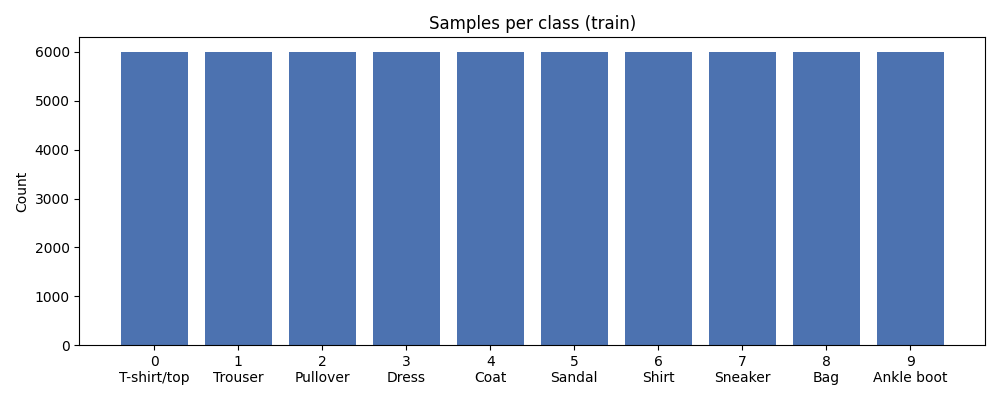

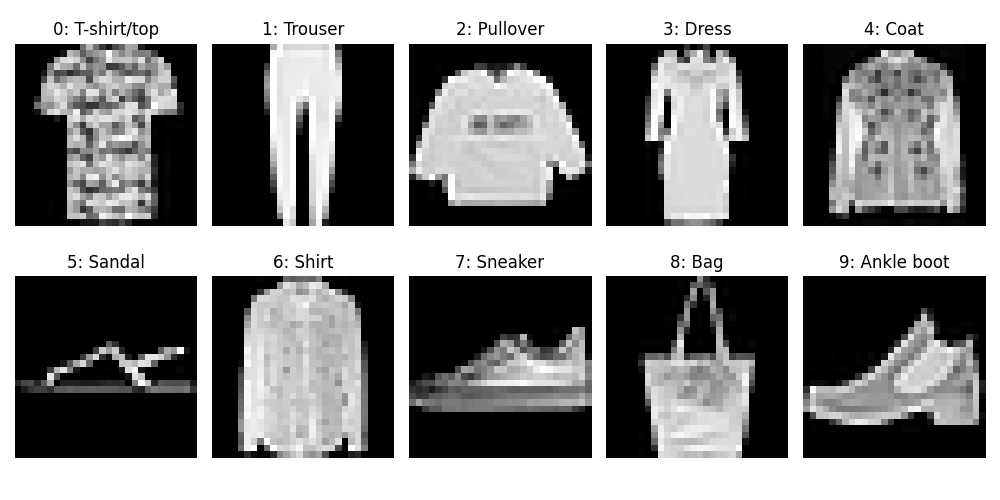

In [2]:
train_csv_path = str(raw_data_dir('lab1') / 'fashion-mnist_train.csv')
figures_dir = artifact_dir('lab1', 'figures')

eda_stats = run_eda(train_csv_path, str(figures_dir))
print(f"Total samples : {eda_stats['n_rows']:,}")
print(f"Missing values: {eda_stats['n_missing']} | Duplicate rows: {eda_stats['n_duplicates']}")
print("Class distribution:", eda_stats['class_counts'])

display(Image(filename=str(figures_dir / 'class_counts.png')))
display(Image(filename=str(figures_dir / 'sample_grid.png')))


### Stage 2: Preprocessing & Stratified Splitting (`labs.lab1.preprocessing`)
We load pixel values as `uint8 [N, 28, 28]` and labels as `int64 [N]`.
We construct a reproducible 90/10 stratified split (`seed=42`):
- **Training set**: 54,000 samples (5,400 per class).
- **Validation set**: 6,000 samples (exactly 600 per class).
- **Persistence**: Indices are saved to `train_val_split.json` so that all modules and teammates use the exact same partition.

*Why Stratified Splitting?* Stratification enforces identical class proportions across both training and validation sets, preventing random sampling skew.

In [3]:
test_csv_path = str(raw_data_dir('lab1') / 'fashion-mnist_test.csv')
splits_dir = artifact_dir('lab1', 'splits')
split_file = str(splits_dir / 'train_val_split.json')

images, labels = load_csv(train_csv_path)
test_images, test_labels = load_csv(test_csv_path)

if Path(split_file).is_file():
    train_idx, val_idx = load_split(split_file)
else:
    train_idx, val_idx = make_split(labels, val_ratio=0.1, seed=42)
    save_split(train_idx, val_idx, split_file)

print(f"Train images shape : {images.shape}, dtype: {images.dtype}")
print(f"Split partitions   : Train = {len(train_idx):,} | Val = {len(val_idx):,} | Test = {len(test_labels):,}")

val_labels = labels[val_idx]
_, counts = np.unique(val_labels, return_counts=True)
print(f"Validation samples per class (all 600): {dict(enumerate(counts))}")


Train images shape : (60000, 28, 28), dtype: uint8
Split partitions   : Train = 54,000 | Val = 6,000 | Test = 10,000
Validation samples per class (all 600): {0: np.int64(600), 1: np.int64(600), 2: np.int64(600), 3: np.int64(600), 4: np.int64(600), 5: np.int64(600), 6: np.int64(600), 7: np.int64(600), 8: np.int64(600), 9: np.int64(600)}


### Stage 3: Feature Engineering & DataLoaders (`labs.lab1.features`)
We standardize pixel values to zero mean and unit variance:
- **Train-Only Normalization**: Mean ($\mu$) and standard deviation ($\sigma$) are computed **strictly from the 54,000 training images**. The identical transform is applied to validation and test images.
- **Data Leakage Prevention**: Calculating normalization statistics across the entire dataset would leak distribution parameters from unseen sets into the model.
- Images are cast to PyTorch `float32` tensors `[1, 28, 28]` and loaded with `batch_size = 64` (shuffled only during training).

In [4]:
mean, std = compute_mean_std(images[train_idx])
transform = build_transform(mean, std)
print(f"Train-only Normalization Stats: mean = {mean:.4f}, std = {std:.4f}")

train_ds = FashionDataset(images, labels, indices=train_idx, transform=transform)
val_ds = FashionDataset(images, labels, indices=val_idx, transform=transform)
test_ds = FashionDataset(test_images, test_labels, indices=None, transform=transform)

train_loader, val_loader, test_loader = make_loaders(train_ds, val_ds, test_ds, batch_size=64)

# Verify a sample batch
sample_batch_x, sample_batch_y = next(iter(train_loader))
print(f"Batch X tensor shape   : {sample_batch_x.shape}, dtype: {sample_batch_x.dtype}")
print(f"Batch Y tensor shape   : {sample_batch_y.shape}, dtype: {sample_batch_y.dtype}")
print(f"Batch normalized range : min = {sample_batch_x.min():.2f}, max = {sample_batch_x.max():.2f}")


Train-only Normalization Stats: mean = 0.2860, std = 0.3527
Batch X tensor shape   : torch.Size([64, 1, 28, 28]), dtype: torch.float32
Batch Y tensor shape   : torch.Size([64]), dtype: torch.int64
Batch normalized range : min = -0.81, max = 2.02


### Stage 4: Model Architecture & Parameter Audit (`labs.lab1.model`)
We construct a fully-connected Multi-Layer Perceptron (MLP):
- **Input**: Flattened $28 \times 28 = 784$ grayscale image vector.
- **Hidden Layer 1**: Linear(784, 256) + ReLU $\to 784 \times 256 + 256 = 200,960$ parameters.
- **Hidden Layer 2**: Linear(256, 128) + ReLU $\to 256 \times 128 + 128 = 32,896$ parameters.
- **Output Layer**: Linear(128, 10) $\to 128 \times 10 + 10 = 1,290$ parameters.
- **Total Trainable Parameters**: $200,960 + 32,896 + 1,290 = 235,146$.

```mermaid
flowchart LR
    In["Input<br/>[B, 1, 28, 28]"] --> Flat["Flatten<br/>[B, 784]"]
    Flat --> L1["Linear(784, 256)"] --> R1["ReLU"]
    R1 --> L2["Linear(256, 128)"] --> R2["ReLU"]
    R2 --> L3["Linear(128, 10)"] --> Out["Raw Logits<br/>[B, 10]"]
```

*Why Raw Logits?* The model outputs unscaled logits rather than Softmax probabilities because `torch.nn.CrossEntropyLoss` combines `LogSoftmax` and `NLLLoss` internally, providing superior numerical stability.

In [5]:
# Reset seed prior to instantiation for deterministic weight initialization
set_seed(42)
model = MLP(hidden_sizes=(256, 128), num_classes=10, dropout=0.0).to(device)
total_params = count_parameters(model)

print(model)
print(f"\nTotal trainable parameters: {total_params:,}")

# Verify forward pass with dummy tensor
dummy_input = torch.randn(4, 1, 28, 28, device=device)
dummy_logits = model(dummy_input)
print(f"Dummy output logits shape : {dummy_logits.shape} (expected [4, 10])")


MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total trainable parameters: 235,146
Dummy output logits shape : torch.Size([4, 10]) (expected [4, 10])


### Stage 5: Training Baseline Model (`labs.lab1.train`)
We train the baseline model for 5 epochs:
- **Optimization**: Adam optimizer with learning rate $\text{lr} = 10^{-3}$ and `weight_decay = 0.0`.
- **Sample-Weighted Loss**: Per-batch losses are weighted by batch size (`loss.item() * batch_size`) and divided by total samples, ensuring exact epoch loss even if the final batch has fewer than 64 samples.
- **Checkpoint Selection**: The best model weights are checkpointed to `artifacts/models/mlp_baseline.pt` based strictly on lowest validation loss (minimizing overconfidence and overfitting).

In [6]:
models_dir = artifact_dir('lab1', 'models')
ckpt_path = str(models_dir / 'mlp_baseline.pt')

epochs = 5
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=epochs,
    lr=1e-3,
    device=device,
    ckpt_path=ckpt_path,
    optimizer_name='adam',
    weight_decay=0.0
)

print(f"\nCheckpoint saved to: {ckpt_path}")
print("Training history across epochs:")
for ep in range(epochs):
    t_loss = history['train_loss'][ep]
    v_loss = history['val_loss'][ep]
    v_acc = history['val_acc'][ep]
    print(f"  Epoch {ep+1}/{epochs}: Train Loss = {t_loss:.4f} | Val Loss = {v_loss:.4f} | Val Acc = {v_acc*100:.2f}%")



Checkpoint saved to: D:\MON_HOC\Nam-3-HK1\DOT-1\DL\Lab-DL\labs\lab1\artifacts\models\mlp_baseline.pt
Training history across epochs:
  Epoch 1/5: Train Loss = 0.4785 | Val Loss = 0.3744 | Val Acc = 87.10%
  Epoch 2/5: Train Loss = 0.3532 | Val Loss = 0.3481 | Val Acc = 87.72%
  Epoch 3/5: Train Loss = 0.3151 | Val Loss = 0.3266 | Val Acc = 88.87%
  Epoch 4/5: Train Loss = 0.2898 | Val Loss = 0.3194 | Val Acc = 88.77%
  Epoch 5/5: Train Loss = 0.2705 | Val Loss = 0.3310 | Val Acc = 88.60%


### Stage 6: Validation Evaluation & Confusion Matrix (`labs.lab1.evaluate`)
We reload the saved best checkpoint using `load_checkpoint` (evaluation mode, zero gradients).
We compute overall validation loss, validation accuracy, and the $10 \times 10$ confusion matrix.
We also construct a detailed per-class diagnostic report:
- **Precision**: $\frac{TP}{TP + FP}$ — exactness of positive predictions.
- **Recall (TPR)**: $\frac{TP}{TP + FN}$ — proportion of actual positives correctly identified.
- **Specificity (TNR)**: $\frac{TN}{TN + FP}$ — proportion of actual negatives correctly rejected.
- **F1-Score**: Harmonic mean of Precision and Recall: $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$.

In [7]:
eval_model = MLP(hidden_sizes=(256, 128), num_classes=10, dropout=0.0)
best_model = load_checkpoint(eval_model, ckpt_path, device=device)

val_loss, val_acc = evaluate(best_model, val_loader, device=device)
cm = confusion_matrix(best_model, val_loader, device=device, num_classes=10)

# Build detailed per-class diagnostic report
report_rows = []
for i, name in enumerate(CLASS_NAMES):
    tp = cm[i, i]
    fn = cm[i].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - (tp + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    support = cm[i].sum()
    report_rows.append({
        "Class ID": i,
        "Class Name": name,
        "Support": support,
        "Precision": f"{precision*100:.2f}%",
        "Recall (TPR)": f"{recall*100:.2f}%",
        "Specificity (TNR)": f"{specificity*100:.2f}%",
        "F1-Score": f"{f1*100:.2f}%"
    })

df_report = pd.DataFrame(report_rows)
print(f"Validation Loss    : {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc*100:.2f}% ({int(round(val_acc*len(val_ds)))}/{len(val_ds)})")
print("\n=== Comprehensive Classification Report (Validation Split) ===")
display(df_report)


Validation Loss    : 0.3194
Validation Accuracy: 88.77% (5326/6000)

=== Comprehensive Classification Report (Validation Split) ===


,Class ID,Class Name,Support,Precision,Recall (TPR),Specificity (TNR),F1-Score
0,0,T-shirt/top,600,89.66%,75.17%,99.04%,81.78%
1,1,Trouser,600,98.99%,98.50%,99.89%,98.75%
2,2,Pullover,600,76.00%,85.50%,97.00%,80.47%
3,3,Dress,600,86.83%,92.33%,98.44%,89.50%
4,4,Coat,600,80.47%,79.67%,97.85%,80.07%
5,5,Sandal,600,98.79%,95.00%,99.87%,96.86%
6,6,Shirt,600,72.70%,71.00%,97.04%,71.84%
7,7,Sneaker,600,92.90%,96.00%,99.19%,94.43%
8,8,Bag,600,96.71%,97.83%,99.63%,97.27%
9,9,Ankle boot,600,96.19%,96.67%,99.57%,96.43%


### Stage 7: Error Analysis — Shirt Misclassification Study
In the classification report above, **Shirt (Class 6)** exhibits the lowest recognition accuracy (Recall $\approx 71\%$, F1 $\approx 72\%$).
We extract and visually inspect validation samples of the Shirt class that were incorrectly predicted by the model.

**Technical Root Causes for Shirt Misclassification:**
1. **Low-resolution pixel degradation (28x28 grayscale)**: Critical visual markers distinguishing a buttoned shirt (collar folds, button placket, cuffs) become blurred after downsampling.
2. **Silhouette and texture overlap**: The overall shape of a Shirt strongly resembles `T-shirt/top`, `Pullover`, and `Coat`.
3. **Absence of spatial convolutions**: The MLP flattens 2D images into 1D vectors of 784 numbers, losing local 2D spatial relationships and structural receptive fields that a CNN would retain.

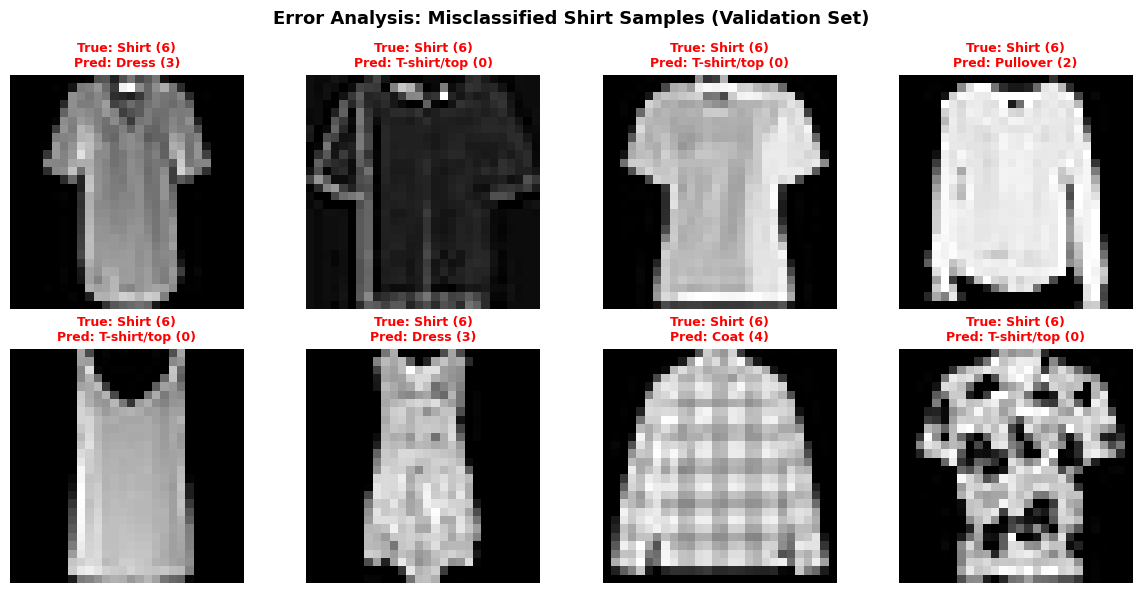

Observation: Most misclassified shirts are predicted as T-shirt/top, Pullover, or Coat due to upper-body silhouette similarities.


In [8]:
shirt_class_id = 6
misclassified_shirts = []

best_model.eval()
with torch.no_grad():
    for x_b, y_b in val_loader:
        logits = best_model(x_b.to(device))
        preds = torch.argmax(logits, dim=1).cpu()
        for img, true_lbl, pred_lbl in zip(x_b, y_b, preds):
            if true_lbl.item() == shirt_class_id and pred_lbl.item() != shirt_class_id:
                # Un-normalize image: x_raw = x_norm * std + mean
                img_raw = (img.squeeze(0).cpu().numpy() * std + mean).clip(0, 1)
                misclassified_shirts.append((img_raw, pred_lbl.item()))
            if len(misclassified_shirts) >= 8:
                break
        if len(misclassified_shirts) >= 8:
            break

# Plot 2x4 grid of misclassified shirt images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for idx, (img_arr, p_lbl) in enumerate(misclassified_shirts[:8]):
    ax = axes[idx // 4, idx % 4]
    ax.imshow(img_arr, cmap='gray')
    ax.set_title(f"True: Shirt (6)\nPred: {CLASS_NAMES[p_lbl]} ({p_lbl})", color='red', fontsize=9, fontweight='bold')
    ax.axis('off')

plt.suptitle("Error Analysis: Misclassified Shirt Samples (Validation Set)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Observation: Most misclassified shirts are predicted as T-shirt/top, Pullover, or Coat due to upper-body silhouette similarities.")


### Stage 8: Visual Diagnostics (`labs.lab1.visualize`)
We generate and visually inspect three primary diagnostic figures:
1. **Loss Curves**: Training vs validation loss trajectories over 5 epochs. A widening gap between train loss ($\approx 0.27$) and val loss ($\approx 0.32$) indicates an early tendency toward mild overfitting.
2. **Predictions Grid**: 16 validation samples with predicted and ground-truth labels (green for correct, red for errors).
3. **Confusion Matrix Heatmap**: Annotated cell counts showing where classification errors concentrate.

1. Loss Curves Trajectory:


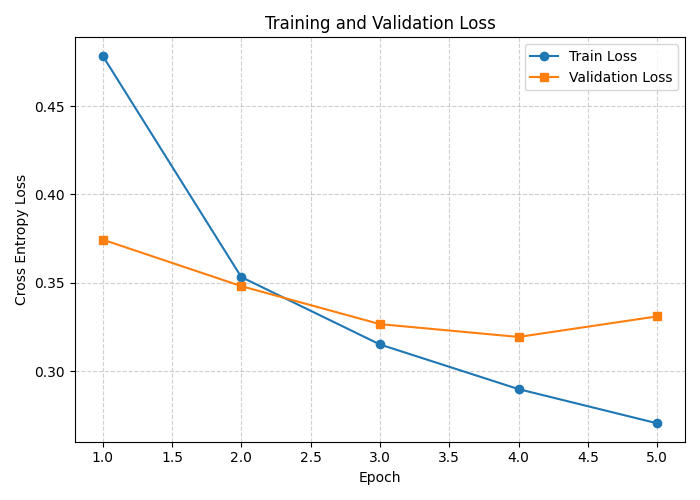


2. Sample Predictions Grid (Green = Correct, Red = Error):


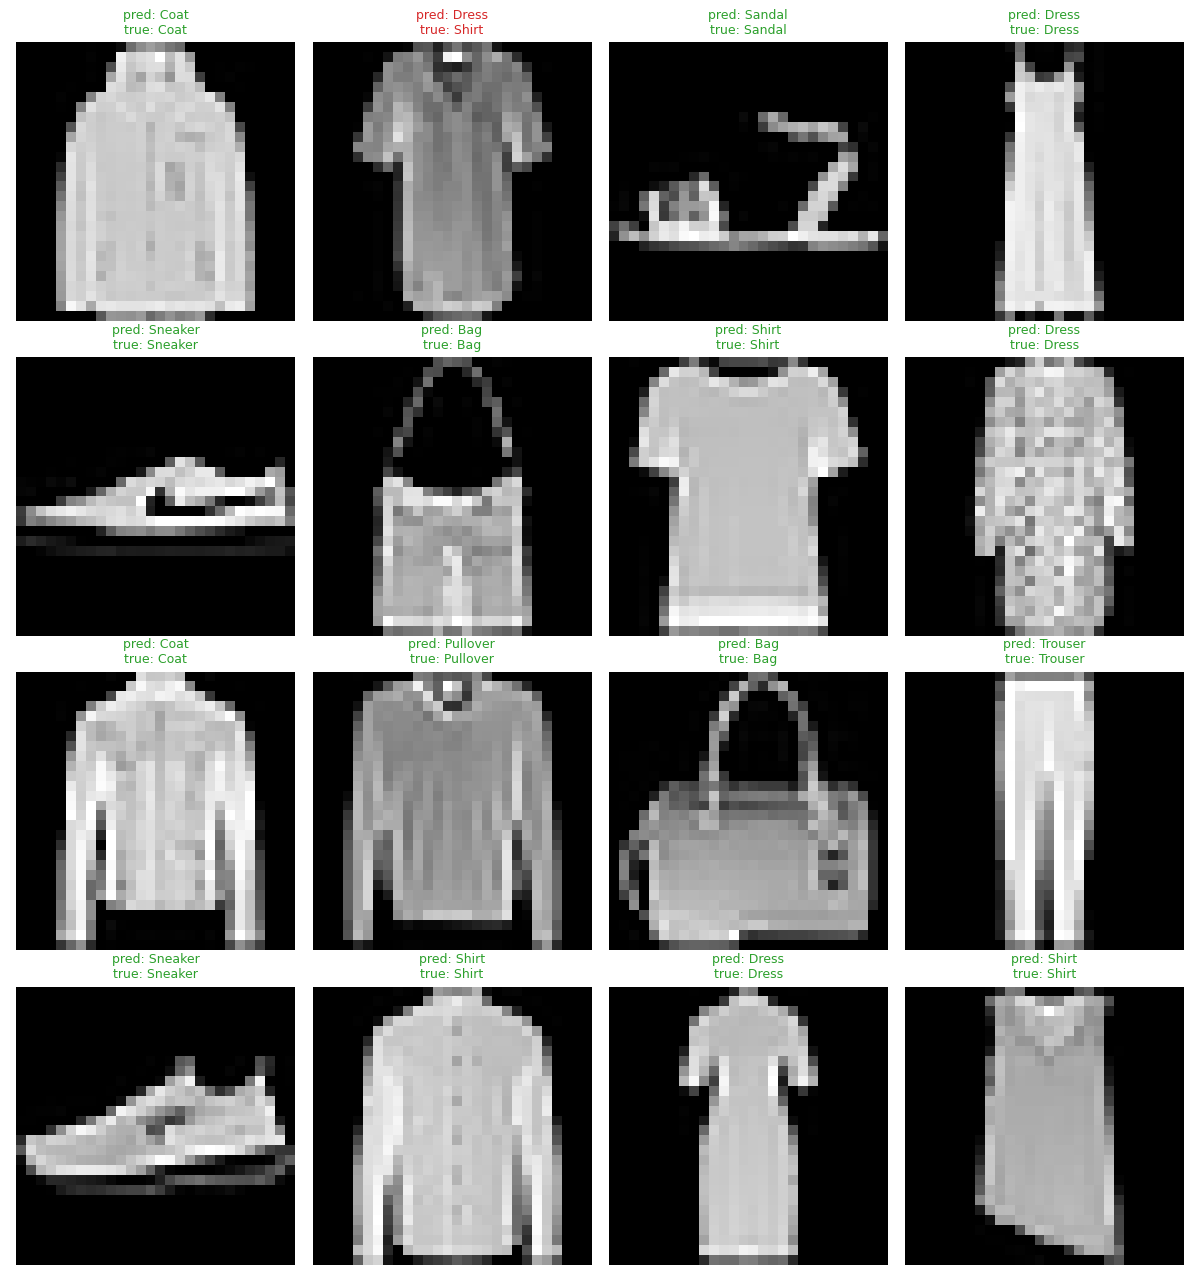


3. Confusion Matrix Heatmap:


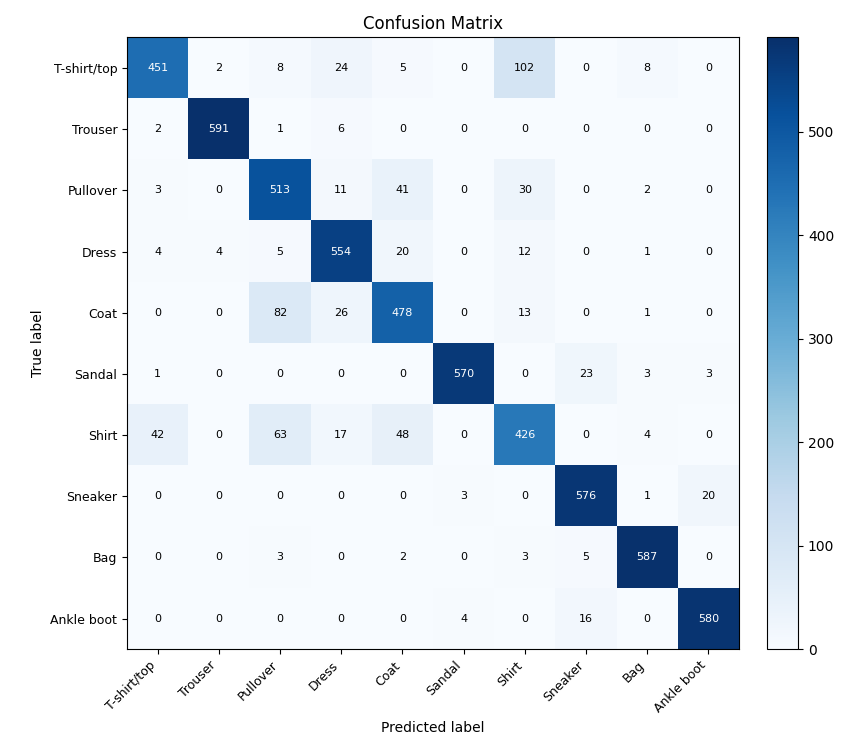

In [9]:
loss_fig_path = str(figures_dir / 'loss_curves.png')
pred_fig_path = str(figures_dir / 'predictions_grid.png')
cm_fig_path = str(figures_dir / 'confusion_matrix.png')

plot_loss_curves(history, loss_fig_path)
show_predictions(best_model, val_loader, CLASS_NAMES, device=device, out_path=pred_fig_path, n=16)
plot_confusion_matrix(cm, CLASS_NAMES, cm_fig_path)

print("1. Loss Curves Trajectory:")
display(Image(filename=loss_fig_path))

print("\n2. Sample Predictions Grid (Green = Correct, Red = Error):")
display(Image(filename=pred_fig_path))

print("\n3. Confusion Matrix Heatmap:")
display(Image(filename=cm_fig_path))


### Stage 9: Controlled Ablation Experiments (`labs.lab1.experiment`)
We benchmark 4 controlled configurations on validation data (`seed=42`):
1. `baseline`: 256-128 hidden units, Adam optimizer (lr=1e-3).
2. `optimizer_sgd`: Baseline architecture with SGD and Momentum=0.9 (lr=0.01).
3. `larger_network`: Deeper, wider network (512-256-128, 567k parameters), Adam (lr=1e-3).
4. `with_dropout_reg`: Baseline architecture with Dropout=0.2 and weight decay=1e-4, Adam (lr=1e-3).

**Statistical Noise Consideration**: Accuracy across all 4 configurations spans approximately $88.1\% - 89.1\%$ (a difference of $\approx 0.95$ percentage points). On a validation sample of 6,000 images, standard sampling error is approximately $\pm 0.4\%$. Therefore, minor accuracy variations fall within expected run-to-run variance. The baseline architecture is selected because it offers an effective balance of compact size (235k parameters) and solid empirical performance.

=== Controlled Ablation Experiment Results ===


,Model Name,Hidden Sizes,Optimizer,Params (k),Val Acc (%),Train Time (s)
0,baseline,256-128,adam,235.146,89.05%,32.9s
1,optimizer_sgd,256-128,sgd,235.146,88.57%,37.9s
2,larger_network,512-256-128,adam,567.434,88.10%,54.2s
3,with_dropout_reg,256-128,adam,235.146,88.47%,38.8s


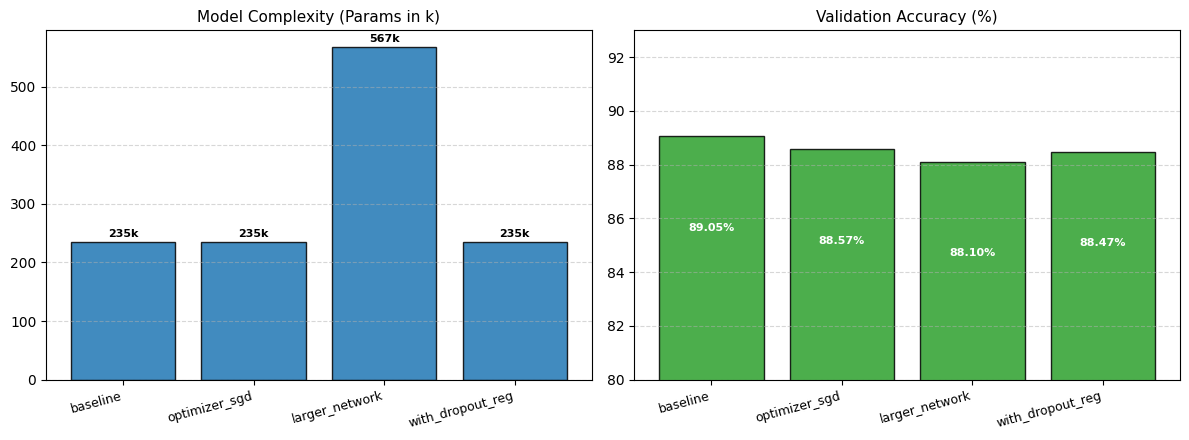

In [10]:
configs = [
    {'name': 'baseline', 'hidden_sizes': (256, 128), 'lr': 1e-3, 'dropout': 0.0, 'optimizer_name': 'adam', 'weight_decay': 0.0, 'epochs': 5, 'seed': 42},
    {'name': 'optimizer_sgd', 'hidden_sizes': (256, 128), 'lr': 0.01, 'dropout': 0.0, 'optimizer_name': 'sgd', 'weight_decay': 0.0, 'epochs': 5, 'seed': 42},
    {'name': 'larger_network', 'hidden_sizes': (512, 256, 128), 'lr': 1e-3, 'dropout': 0.0, 'optimizer_name': 'adam', 'weight_decay': 0.0, 'epochs': 5, 'seed': 42},
    {'name': 'with_dropout_reg', 'hidden_sizes': (256, 128), 'lr': 1e-3, 'dropout': 0.2, 'optimizer_name': 'adam', 'weight_decay': 1e-4, 'epochs': 5, 'seed': 42},
]

results = run_experiments(configs, (train_loader, val_loader, test_loader), device=device)
runs_csv = str(artifact_dir('lab1', 'runs') / 'experiment_results.csv')
save_results(results, runs_csv)

rows = []
for r in results:
    c = r['config']
    rows.append({
        "Model Name": c['name'],
        "Hidden Sizes": "-".join(str(x) for x in c['hidden_sizes']),
        "Optimizer": c['optimizer_name'],
        "Params (k)": r['n_params'] / 1000.0,
        "Val Acc (%)": f"{r['best_val_acc']*100:.2f}%",
        "Train Time (s)": f"{r['train_seconds']:.1f}s",
        "_acc": r['best_val_acc'] * 100.0,
        "_params": r['n_params'] / 1000.0
    })

df_exp = pd.DataFrame(rows)
print("=== Controlled Ablation Experiment Results ===")
display(df_exp[['Model Name', 'Hidden Sizes', 'Optimizer', 'Params (k)', 'Val Acc (%)', 'Train Time (s)']])

# 2-Panel Comparison: Model Complexity vs Validation Accuracy
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
names = [row['Model Name'] for row in rows]
x_pos = np.arange(len(names))

# 1. Model Complexity
axes[0].bar(x_pos, [row['_params'] for row in rows], color="#1f77b4", edgecolor="black", alpha=0.85)
for idx, v in enumerate([row['_params'] for row in rows]):
    axes[0].text(idx, v + 8, f"{v:.0f}k", ha="center", fontsize=8, fontweight="bold")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(names, rotation=15, ha="right", fontsize=9)
axes[0].set_title("Model Complexity (Params in k)", fontsize=11)
axes[0].grid(True, axis="y", linestyle="--", alpha=0.5)

# 2. Validation Accuracy
axes[1].bar(x_pos, [row['_acc'] for row in rows], color="#2ca02c", edgecolor="black", alpha=0.85)
for idx, v in enumerate([row['_acc'] for row in rows]):
    axes[1].text(idx, v - 3.5, f"{v:.2f}%", ha="center", color="white", fontsize=8, fontweight="bold")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(names, rotation=15, ha="right", fontsize=9)
axes[1].set_title("Validation Accuracy (%)", fontsize=11)
axes[1].set_ylim(80, 93)
axes[1].grid(True, axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Stage 10: Final Single Evaluation on Unseen Test Set
Following standard machine learning evaluation protocol, the selected baseline model (`mlp_baseline.pt`) is evaluated **exactly once** on the held-out 10,000 test samples (`fashion-mnist_test.csv`).
Hyperparameter selection was finalized exclusively on validation data prior to this test run.

In [11]:
test_loss, test_acc = evaluate(best_model, test_loader, device=device)

print("============================================================")
print("           FINAL TEST SET EVALUATION RESULTS                ")
print("============================================================")
print(f"  Dataset Partition : Kaggle Fashion-MNIST Test Split (10,000 samples)")
print(f"  Model Checkpoint  : {ckpt_path}")
print(f"  Test Loss         : {test_loss:.4f}")
print(f"  Test Accuracy     : {test_acc*100:.2f}% ({int(round(test_acc*len(test_ds)))}/{len(test_ds)} correct)")
print("============================================================")


           FINAL TEST SET EVALUATION RESULTS                
  Dataset Partition : Kaggle Fashion-MNIST Test Split (10,000 samples)
  Model Checkpoint  : D:\MON_HOC\Nam-3-HK1\DOT-1\DL\Lab-DL\labs\lab1\artifacts\models\mlp_baseline.pt
  Test Loss         : 0.3212
  Test Accuracy     : 88.32% (8832/10000 correct)


### Summary & Key Takeaways

1. **Generalization Performance**: The baseline model achieves $\approx 88.8\%$ validation accuracy and an almost identical $\approx 88.3\%$ test accuracy. The close alignment between validation and test scores indicates that computing normalization statistics strictly on the training split prevented distribution leakage.
2. **Error Distribution**: The model classifies distinct silhouettes (Trouser, Sandal, Sneaker, Ankle boot) with high accuracy ($>95\%$), while misclassifications concentrate heavily among upper-body apparel (Shirt, T-shirt, Pullover, Coat) due to visual overlap in low-resolution grayscale images.
3. **Model Architecture Selection**: Expanding network capacity to 567k parameters did not improve 5-epoch validation accuracy over the 235k baseline ($88.10\%$ vs $89.05\%$). Within this training budget, the baseline architecture represents a practical, well-balanced choice.

### Appendix: Multi-Class Decision Diagnostics (ROC-AUC & PR Curves)
*(Supplementary Material — Course Lecture Chapter 2, Slide 14)*

To evaluate class-separability across varying decision thresholds, we compute One-vs-Rest (OvR) Receiver Operating Characteristic (ROC) and Precision-Recall (PR) curves across all 10 categories.
- **One-vs-Rest (OvR)**: Binarizes the 10-class problem into 10 separate binary classification problems (class $i$ vs all other 9 classes).
- **ROC-AUC**: Measures the probability that the model ranks a random positive sample higher than a random negative sample across all thresholds.
- **Precision-Recall Curve**: Evaluates the tradeoff between false positives and false negatives under class-specific probability cutoffs.

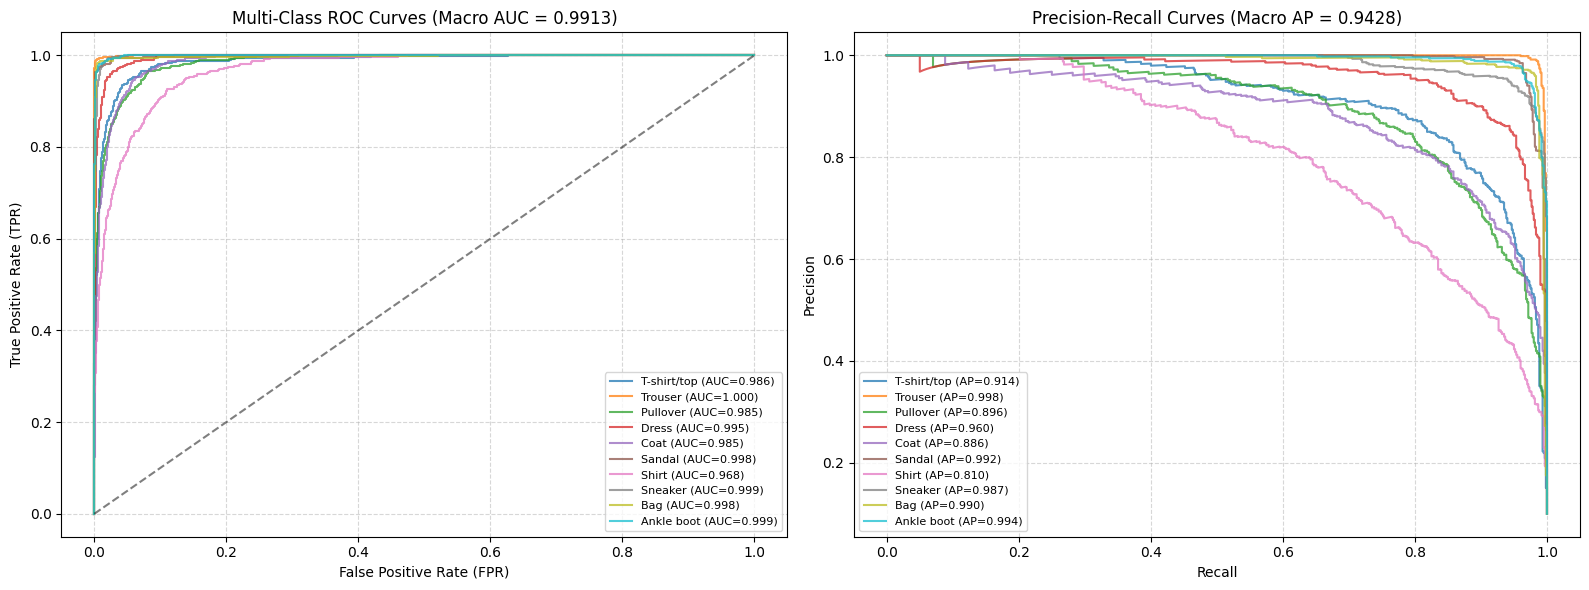

Macro ROC-AUC: 0.9913 | Macro Average Precision (PR-AUC): 0.9428


In [12]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# Collect Softmax probabilities on the validation set
all_probas = []
all_targets = []
best_model.eval()
with torch.no_grad():
    for x_b, y_b in val_loader:
        logits = best_model(x_b.to(device))
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        all_probas.append(probs)
        all_targets.append(y_b.numpy())

all_probas = np.vstack(all_probas)
all_targets = np.concatenate(all_targets)
y_bin = label_binarize(all_targets, classes=list(range(10)))

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(16, 6))

# 1. ROC Curves
roc_aucs = []
for i in range(10):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probas[:, i])
    score = auc(fpr, tpr)
    roc_aucs.append(score)
    ax_roc.plot(fpr, tpr, label=f"{CLASS_NAMES[i]} (AUC={score:.3f})", alpha=0.75)

macro_roc_auc = float(np.mean(roc_aucs))
ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax_roc.set_title(f"Multi-Class ROC Curves (Macro AUC = {macro_roc_auc:.4f})", fontsize=12)
ax_roc.set_xlabel("False Positive Rate (FPR)", fontsize=10)
ax_roc.set_ylabel("True Positive Rate (TPR)", fontsize=10)
ax_roc.legend(fontsize=8, loc="lower right")
ax_roc.grid(True, linestyle="--", alpha=0.5)

# 2. Precision-Recall Curves
ap_scores = []
for i in range(10):
    prec, rec, _ = precision_recall_curve(y_bin[:, i], all_probas[:, i])
    score = average_precision_score(y_bin[:, i], all_probas[:, i])
    ap_scores.append(score)
    ax_pr.plot(rec, prec, label=f"{CLASS_NAMES[i]} (AP={score:.3f})", alpha=0.75)

macro_ap = float(np.mean(ap_scores))
ax_pr.set_title(f"Precision-Recall Curves (Macro AP = {macro_ap:.4f})", fontsize=12)
ax_pr.set_xlabel("Recall", fontsize=10)
ax_pr.set_ylabel("Precision", fontsize=10)
ax_pr.legend(fontsize=8, loc="lower left")
ax_pr.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Macro ROC-AUC: {macro_roc_auc:.4f} | Macro Average Precision (PR-AUC): {macro_ap:.4f}")
